### Library

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import pickle
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, r2_score, mean_absolute_error
from sklearn.ensemble import RandomForestClassifier

d:\Anaconda\lib\site-packages\scipy\__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


### Data Preparation

In [3]:
df = pd.read_csv("data.csv")
df

,Unnamed: 0,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,y
0,0,29,technician,single,basic.9y,no,yes,no,cellular,nov,wed,648.0,1,999,0,nonexistent,no
1,1,31,admin.,single,university.degree,no,no,no,cellular,aug,wed,295.0,1,999,0,nonexistent,no
2,2,27,blue-collar,single,basic.9y,no,yes,no,telephone,jul,mon,236.0,2,999,0,nonexistent,no
3,3,30,services,married,unknown,no,no,no,telephone,may,wed,143.0,3,999,0,nonexistent,no
4,4,32,technician,married,university.degree,no,no,no,cellular,aug,thu,155.0,1,999,0,nonexistent,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8232,8232,33,admin.,single,university.degree,no,no,no,telephone,may,tue,147.0,1,999,0,nonexistent,no
8233,8233,39,blue-collar,married,basic.9y,no,no,no,telephone,may,mon,793.0,5,999,0,nonexistent,no
8234,8234,36,admin.,married,university.degree,no,yes,no,telephone,may,mon,120.0,2,999,0,nonexistent,no
8235,8235,50,admin.,married,university.degree,no,yes,yes,cellular,nov,fri,189.0,2,999,1,failure,no


In [4]:
df = df.drop(columns=['Unnamed: 0', 'month', 'day_of_week'], axis=1)

### EDA

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8237 entries, 0 to 8236
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        8237 non-null   int64  
 1   job        8227 non-null   object 
 2   marital    8237 non-null   object 
 3   education  8237 non-null   object 
 4   default    8237 non-null   object 
 5   housing    8237 non-null   object 
 6   loan       8237 non-null   object 
 7   contact    8237 non-null   object 
 8   duration   8222 non-null   float64
 9   campaign   8237 non-null   int64  
 10  pdays      8237 non-null   int64  
 11  previous   8237 non-null   int64  
 12  poutcome   8237 non-null   object 
 13  y          8237 non-null   object 
dtypes: float64(1), int64(4), object(9)
memory usage: 901.0+ KB


#### Checking Missing Value

In [6]:
df.isnull().sum()

age           0
job          10
marital       0
education     0
default       0
housing       0
loan          0
contact       0
duration     15
campaign      0
pdays         0
previous      0
poutcome      0
y             0
dtype: int64

There is 2 collumn that have missing value

#### Checking Duplicated Row

In [7]:
df.duplicated().sum()

2

Theres 2 rows that duplicated

In [8]:
dups = df[df.duplicated(keep=False)]
print(dups)

      age         job   marital          education default housing loan  \
255    47  technician  divorced        high.school      no     yes   no   
2725   47  technician  divorced        high.school      no     yes   no   
3720   37  management   married  university.degree      no     yes   no   
5301   37  management   married  university.degree      no     yes   no   

        contact  duration  campaign  pdays  previous     poutcome   y  
255    cellular      43.0         3    999         0  nonexistent  no  
2725   cellular      43.0         3    999         0  nonexistent  no  
3720  telephone      97.0         2    999         0  nonexistent  no  
5301  telephone      97.0         2    999         0  nonexistent  no  


#### Data Distribution

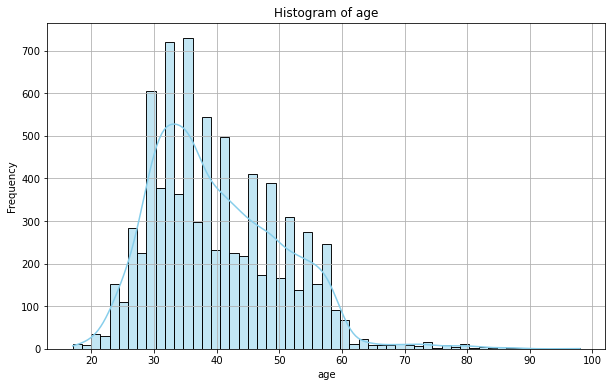

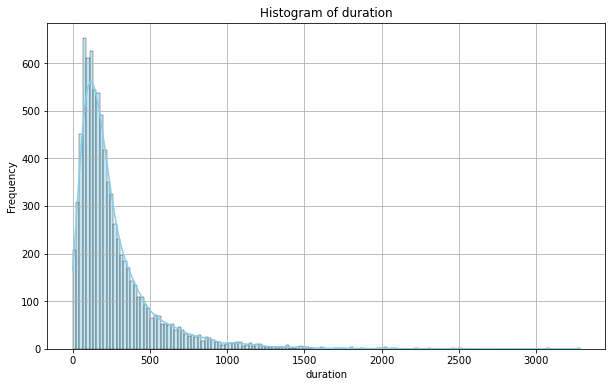

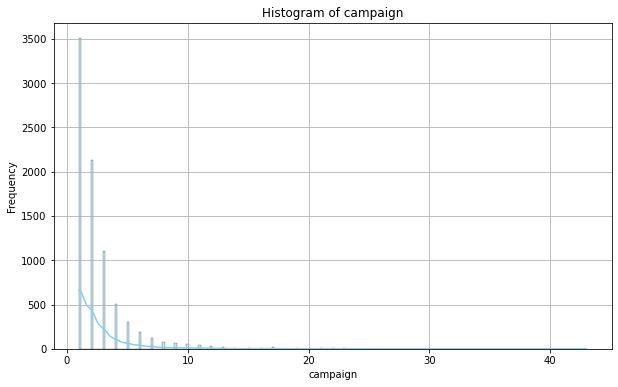

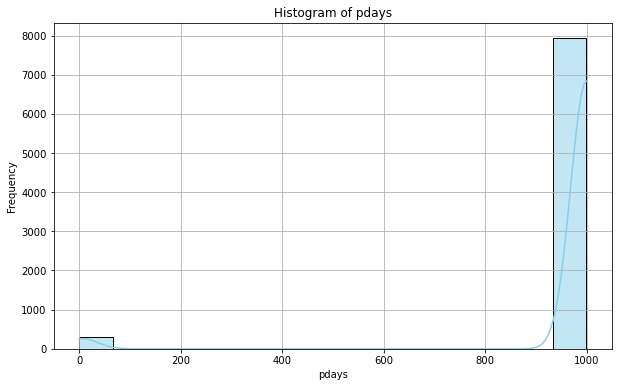

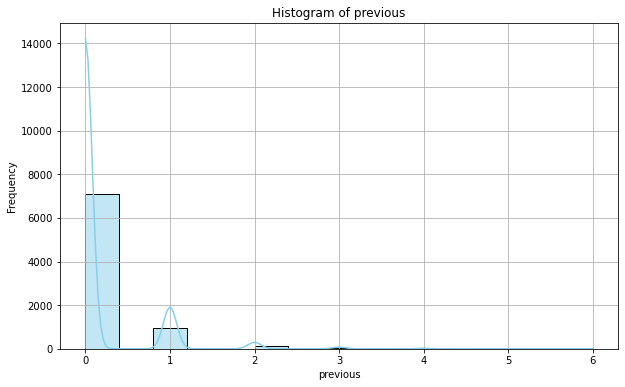

In [9]:
for column in df.columns:
    if pd.api.types.is_numeric_dtype(df[column]):
        plt.figure(figsize=(10, 6))
        sns.histplot(df[column], kde=True, color='skyblue', edgecolor='black')
        plt.title(f'Histogram of {column}')
        plt.xlabel(column)
        plt.ylabel('Frequency')
        plt.grid(True)
        plt.show()

From the graph, the data is imbalanced and not normally distributed

#### Data Corr

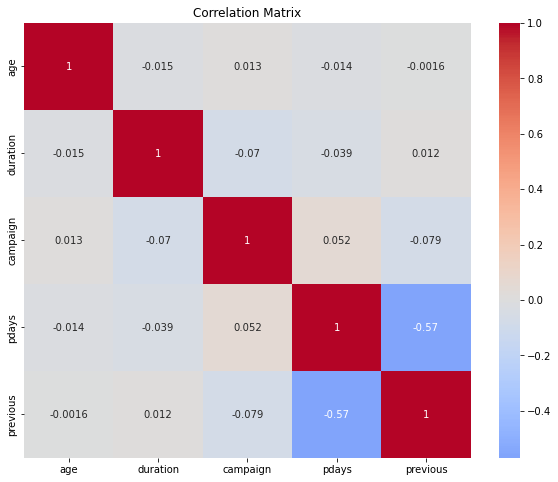

In [10]:
correlation_matrix = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

Theres 2 Highly Correlated Variable

### Encode 

In [11]:
objectCol = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact','poutcome']

In [12]:
label_encoders = {}
for col in objectCol:
    label_encoders[col] = LabelEncoder()
    df[col] = label_encoders[col].fit_transform(df[col])

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8237 entries, 0 to 8236
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        8237 non-null   int64  
 1   job        8237 non-null   int32  
 2   marital    8237 non-null   int32  
 3   education  8237 non-null   int32  
 4   default    8237 non-null   int32  
 5   housing    8237 non-null   int32  
 6   loan       8237 non-null   int32  
 7   contact    8237 non-null   int32  
 8   duration   8222 non-null   float64
 9   campaign   8237 non-null   int64  
 10  pdays      8237 non-null   int64  
 11  previous   8237 non-null   int64  
 12  poutcome   8237 non-null   int32  
 13  y          8237 non-null   object 
dtypes: float64(1), int32(8), int64(4), object(1)
memory usage: 643.6+ KB


### Preprocessing

#### Fill The Missing Value

In [14]:
df['duration'].fillna(df['duration'].mean(), inplace=True)
df['job'].fillna(df['job'].mode()[0], inplace=True)

In [15]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
housing      0
loan         0
contact      0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

#### Drop the duplicated row

In [16]:
df = df.drop_duplicates()

In [17]:
df.duplicated().sum()

0

#### Split Dataset

In [18]:
X, Y = df.drop(columns=['y'], axis=1), df['y']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0)

### Data Scalling

In [19]:
scaler = StandardScaler()

X_train_numercial = X_train.select_dtypes(include=[np.number])
X_test_numerical = X_test.select_dtypes(include=[np.number])

scaler.fit(X_train_numercial)

X_train_numercial = scaler.transform(X_train_numercial)
X_test_numerical = scaler.transform(X_test_numerical)

In [20]:
X_train_numercial = pd.DataFrame(X_train_numercial, columns=X_train.select_dtypes(include=[np.number]).columns)
X_test_numerical = pd.DataFrame(X_test_numerical, columns=X_test.select_dtypes(include=[np.number]).columns)

X_train_numercial.reset_index(drop=True, inplace=True)
X_test_numerical.reset_index(drop=True, inplace=True)

### Model ML

#### Random Forest

In [21]:
rf_classifier = RandomForestClassifier()
rf_classifier.fit(X_train,Y_train)

RandomForestClassifier()

In [22]:
rf_predictions = rf_classifier.predict(X_test)
print(classification_report(Y_test, rf_predictions, target_names=['No', 'Yes']))

              precision    recall  f1-score   support

          No       0.92      0.97      0.95      1467
         Yes       0.57      0.35      0.43       180

    accuracy                           0.90      1647
   macro avg       0.75      0.66      0.69      1647
weighted avg       0.88      0.90      0.89      1647



#### Logistic Regression

In [23]:
log_reg = LogisticRegression()
log_reg.fit(X_train, Y_train)

d:\Anaconda\lib\site-packages\sklearn\linear_model\_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [24]:
log_pred = log_reg.predict(X_test)
print(classification_report(Y_test, log_pred, target_names=['No', 'Yes']))

              precision    recall  f1-score   support

          No       0.92      0.98      0.95      1467
         Yes       0.69      0.31      0.43       180

    accuracy                           0.91      1647
   macro avg       0.81      0.65      0.69      1647
weighted avg       0.90      0.91      0.89      1647



### Saving for Best Model

In [25]:
pickle.dump(log_reg, open('best_model.pkl', 'wb'))